# Loan Default / Risk Prediction

**Course project – Machine Learning**
**Student:** Shreyash Awasthi

---

## 1. Problem Statement
A bank gives loans to thousands of customers, and some of them **fail to repay (default)**.
If the bank can predict *which* loans are likely to default, it can reduce its losses.

**Goal:** Build a machine learning model that predicts whether a loan will default (`1`) or not (`0`)
using customer details and loan details.

**Type of problem:** Supervised learning → **Binary classification**

## 2. Dataset
Three CSV files are provided:

| File | Rows | What it contains |
|---|---|---|
| `customer_financial_data.csv` | 50,000 | Age, gender, income, credit score, total debt, employment status |
| `loan_information_data.csv` | 100,000 | Loan amount, interest rate, loan term, start date |
| `historical_default_data.csv` | 100,000 | The target: `Default` (1 = defaulted, 0 = repaid) |

The files are linked using **`Customer_ID`** (customer ↔ loan) and **`Loan_ID`** (loan ↔ default label).

## 3. Steps followed
1. Load and merge the data  →  2. Data checks  →  3. Exploratory Data Analysis (EDA)
→ 4. Feature engineering  →  5. Model building  →  6. Evaluation  →  7. Conclusion

## Step 1: Import Libraries

In [1]:
import os
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42   # fixed so results are the same every run
print("Libraries imported successfully")

Libraries imported successfully


## Step 2: Load the Data

**Running on Google Colab:** upload `archive.zip` when asked (or drag the 3 CSV files into the *Files* panel on the left).
**Running in VS Code:** keep the 3 CSV files (or `archive.zip`) in the same folder as this notebook.

In [2]:
# Make sure the CSV files are available (works on Colab and locally)
if not os.path.exists("customer_financial_data.csv"):
    if not os.path.exists("archive.zip"):
        try:
            from google.colab import files      # only exists on Colab
            print("Please upload archive.zip")
            files.upload()
        except ImportError:
            raise FileNotFoundError("Put archive.zip or the 3 CSV files in the same folder as this notebook.")
    with zipfile.ZipFile("archive.zip") as z:
        z.extractall(".")

customers = pd.read_csv("customer_financial_data.csv")
loans     = pd.read_csv("loan_information_data.csv")
defaults  = pd.read_csv("historical_default_data.csv")

print("Customers :", customers.shape)
print("Loans     :", loans.shape)
print("Defaults  :", defaults.shape)

Customers : (50000, 8)
Loans     : (100000, 6)
Defaults  : (100000, 2)


In [3]:
customers.head()

,Customer_ID,Name,Age,Gender,Annual_Income,Credit_Score,Total_Debt,Employment_Status
0,C00000001,David Taylor,56,Male,133324.57,409,46843.40,Unemployed
1,C00000002,Edward Grant,69,Male,161664.22,771,34325.10,Unemployed
2,C00000003,Robert Mosley,46,Male,41999.98,696,45115.08,Unemployed
3,C00000004,Emily Cunningham,32,Male,125164.68,657,13464.71,Self-Employed
4,C00000005,Mr. Jorge Gordon,60,Male,35377.38,811,35849.70,Self-Employed


In [4]:
loans.head()

,Loan_ID,Customer_ID,Loan_Amount,Interest_Rate,Loan_Term,Loan_Start_Date
0,L00000001,C00026785,40594.38,13.93,60 months,2024-06-04
1,L00000002,C00011497,38966.87,5.90,12 months,2023-09-02
2,L00000003,C00007333,29180.92,8.56,60 months,2020-08-08
3,L00000004,C00021003,31714.71,9.48,48 months,2024-06-17
4,L00000005,C00026374,19542.04,12.19,24 months,2022-10-03


In [5]:
defaults.head()

,Loan_ID,Default
0,L00000001,0
1,L00000002,0
2,L00000003,0
3,L00000004,0
4,L00000005,0


## Step 3: Merge the Three Tables into One

- `loans` + `defaults` → joined on **Loan_ID** (each loan gets its label)
- then + `customers` → joined on **Customer_ID** (each loan gets its customer's details)

We use a **left join** starting from `loans`, so every loan is kept.

In [6]:
df = loans.merge(defaults, on="Loan_ID", how="left")
df = df.merge(customers, on="Customer_ID", how="left")

print("Merged shape:", df.shape)
df.head()

Merged shape: (100000, 14)


,Loan_ID,Customer_ID,Loan_Amount,Interest_Rate,Loan_Term,Loan_Start_Date,Default,Name,Age,Gender,Annual_Income,Credit_Score,Total_Debt,Employment_Status
0,L00000001,C00026785,40594.38,13.93,60 months,2024-06-04,0,Jimmy Smith,46,Male,102522.56,746,24487.40,Unemployed
1,L00000002,C00011497,38966.87,5.90,12 months,2023-09-02,0,Jennifer Ramirez,27,Male,83159.68,468,31885.15,Self-Employed
2,L00000003,C00007333,29180.92,8.56,60 months,2020-08-08,0,Randy Livingston,43,Female,42259.73,765,9312.03,Unemployed
3,L00000004,C00021003,31714.71,9.48,48 months,2024-06-17,0,Cynthia Boyer,58,Female,33451.08,352,42480.11,Employed
4,L00000005,C00026374,19542.04,12.19,24 months,2022-10-03,0,Brandon Hamilton,50,Male,124924.48,362,8041.98,Self-Employed


## Step 4: Data Quality Checks

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Loan_IDs:", df["Loan_ID"].duplicated().sum())

Missing values per column:
Loan_ID              0
Customer_ID          0
Loan_Amount          0
Interest_Rate        0
Loan_Term            0
Loan_Start_Date      0
Default              0
Name                 0
Age                  0
Gender               0
Annual_Income        0
Credit_Score         0
Total_Debt           0
Employment_Status    0
dtype: int64



Duplicate rows: 0
Duplicate Loan_IDs: 0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Loan_ID            100000 non-null  str    
 1   Customer_ID        100000 non-null  str    
 2   Loan_Amount        100000 non-null  float64
 3   Interest_Rate      100000 non-null  float64
 4   Loan_Term          100000 non-null  str    
 5   Loan_Start_Date    100000 non-null  str    
 6   Default            100000 non-null  int64  
 7   Name               100000 non-null  str    
 8   Age                100000 non-null  int64  
 9   Gender             100000 non-null  str    
 10  Annual_Income      100000 non-null  float64
 11  Credit_Score       100000 non-null  int64  
 12  Total_Debt         100000 non-null  float64
 13  Employment_Status  100000 non-null  str    
dtypes: float64(4), int64(3), str(7)
memory usage: 10.7 MB


In [9]:
df.describe().round(2)

,Loan_Amount,Interest_Rate,Default,Age,Annual_Income,Credit_Score,Total_Debt
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,25463.42,8.76,0.15,43.50,110037.55,573.32,25008.85
std,14140.16,3.60,0.36,14.98,51932.95,159.16,14440.52
min,1000.11,2.50,0.00,18.00,20001.52,300.00,0.24
25%,13205.84,5.64,0.00,31.00,64641.62,434.00,12454.26
50%,25439.71,8.78,0.00,43.00,110469.23,573.00,24989.53
75%,37713.07,11.86,0.00,57.00,155140.49,712.00,37468.60
max,49999.74,15.00,1.00,69.00,199998.57,849.00,49999.15


**Observations**
- No missing values and no duplicate rows, so no cleaning is needed.
- `Loan_Term` is text (e.g. `"60 months"`), so we will convert it to a number.
- Credit score ranges from 300 to 850, which is the normal credit-score scale.

## Step 5: Exploratory Data Analysis (EDA)

### 5.1 How many loans defaulted? (Target variable)

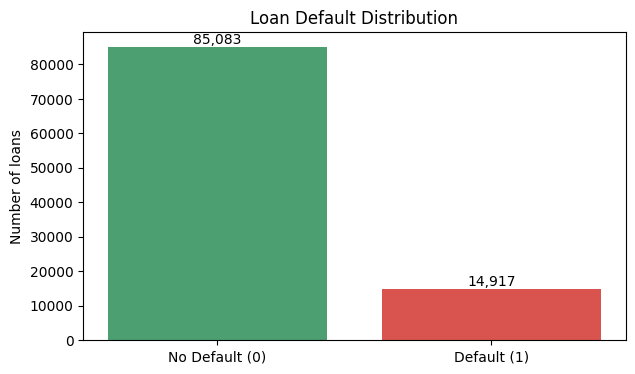

Default rate: 14.92%


In [10]:
counts = df["Default"].value_counts().sort_index()
rate = df["Default"].mean() * 100

fig, ax = plt.subplots()
ax.bar(["No Default (0)", "Default (1)"], counts.values, color=["#4c9f70", "#d9534f"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 800, f"{v:,}", ha="center")
ax.set_title("Loan Default Distribution")
ax.set_ylabel("Number of loans")
plt.show()

print(f"Default rate: {rate:.2f}%")

**Observation:** Only about **15%** of loans default, so the data is **imbalanced**.
This matters a lot: a useless model that says *"nobody will default"* would still be ~85% accurate.
So **accuracy alone is a misleading metric here** — we will also use precision, recall, F1 and ROC-AUC.

### 5.2 Distribution of numeric features

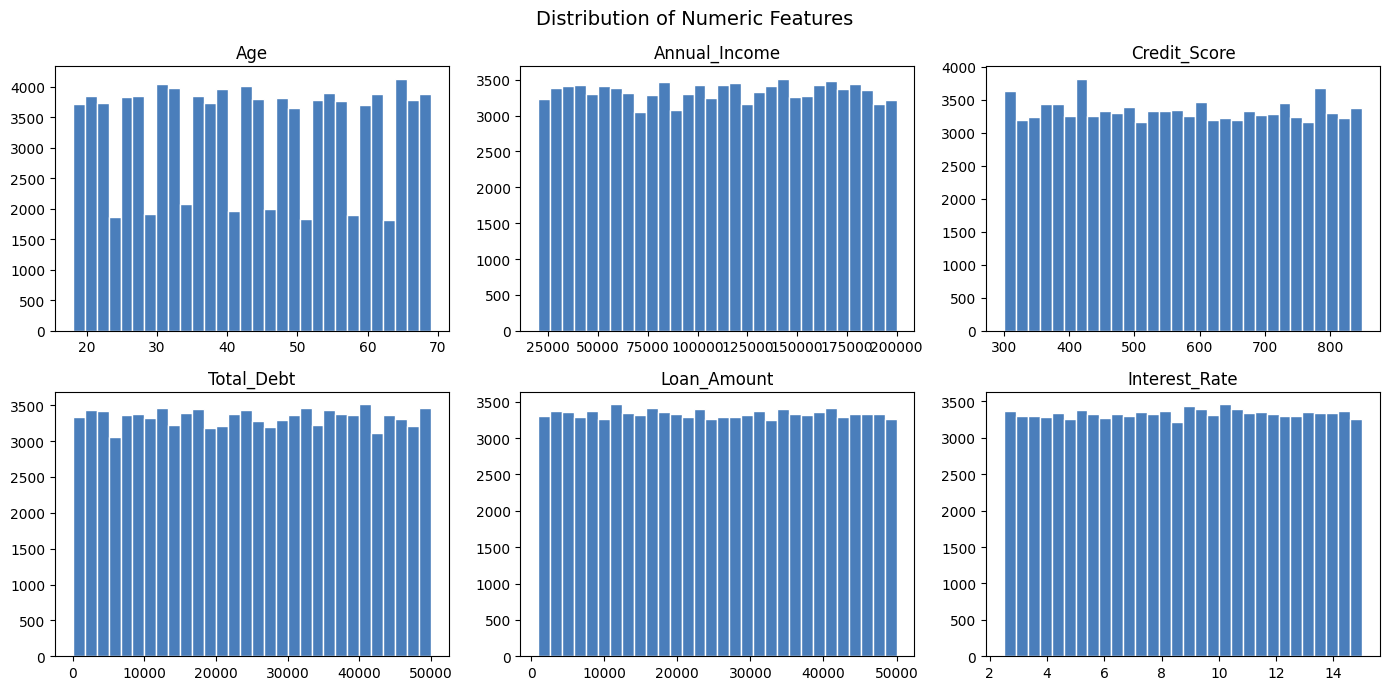

In [11]:
num_cols = ["Age", "Annual_Income", "Credit_Score", "Total_Debt", "Loan_Amount", "Interest_Rate"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=30, color="#4a7ebb", edgecolor="white")
    ax.set_title(col)
plt.suptitle("Distribution of Numeric Features", fontsize=14)
plt.tight_layout()
plt.show()

### 5.3 Do defaulters look different from non-defaulters?

In [12]:
# Average of each numeric feature for the two groups
df.groupby("Default")[num_cols].mean().round(2)

,Age,Annual_Income,Credit_Score,Total_Debt,Loan_Amount,Interest_Rate
Default,,,,,,
0,43.49,110014.47,573.62,24995.00,25474.21,8.75
1,43.57,110169.17,571.55,25087.87,25401.83,8.79


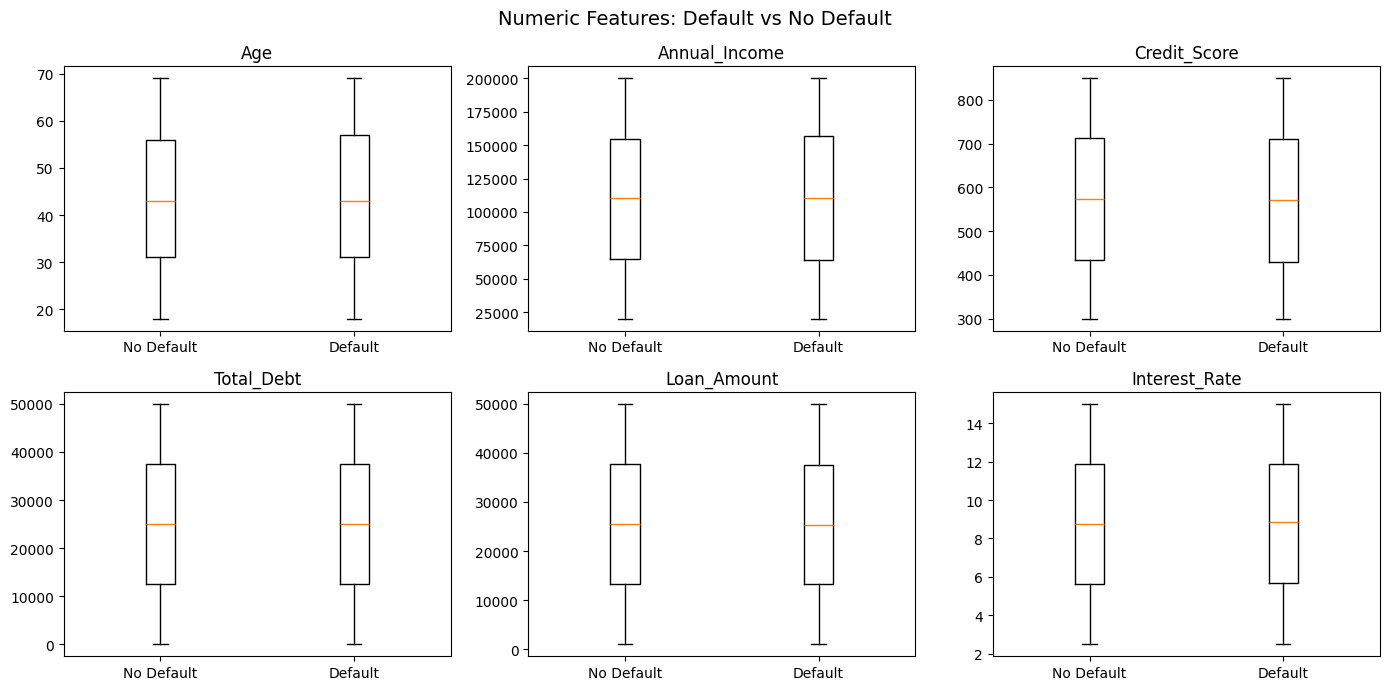

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    data = [df.loc[df["Default"] == 0, col], df.loc[df["Default"] == 1, col]]
    ax.boxplot(data)
    ax.set_xticklabels(["No Default", "Default"])
    ax.set_title(col)
plt.suptitle("Numeric Features: Default vs No Default", fontsize=14)
plt.tight_layout()
plt.show()

### 5.4 Default rate by category

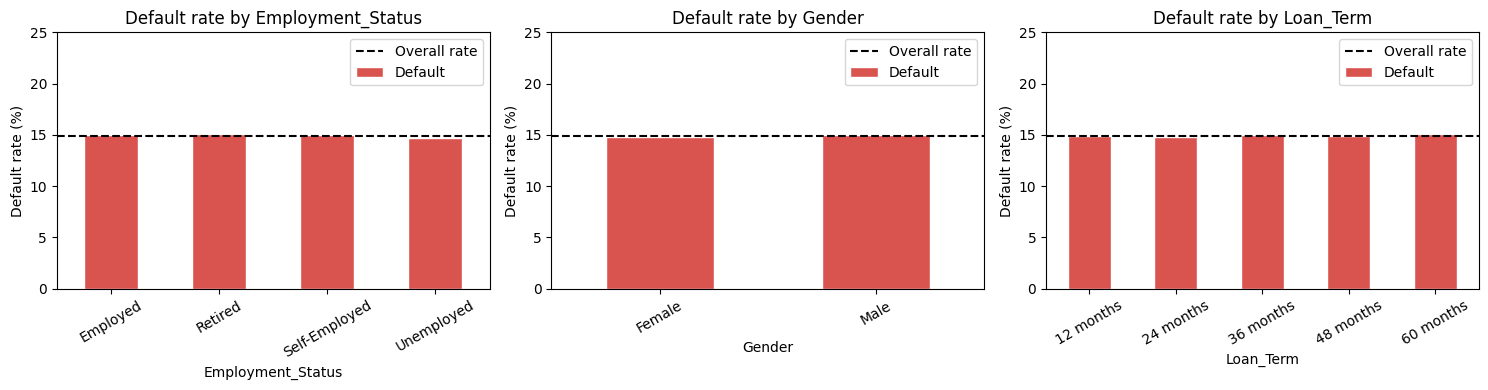

In [14]:
def plot_default_rate(column, ax):
    rate = df.groupby(column)["Default"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#d9534f", edgecolor="white")
    ax.axhline(df["Default"].mean() * 100, color="black", linestyle="--", label="Overall rate")
    ax.set_title(f"Default rate by {column}")
    ax.set_ylabel("Default rate (%)")
    ax.set_ylim(0, 25)
    ax.tick_params(axis="x", rotation=30)
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_default_rate("Employment_Status", axes[0])
plot_default_rate("Gender", axes[1])
plot_default_rate("Loan_Term", axes[2])
plt.tight_layout()
plt.show()

### 5.5 Default rate by credit score band

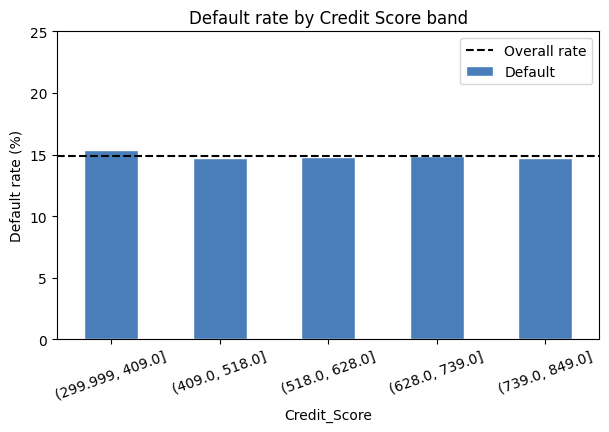

In [15]:
# Split credit score into 5 equal-sized groups (quintiles)
score_band = pd.qcut(df["Credit_Score"], 5)
rate_by_score = df.groupby(score_band)["Default"].mean() * 100

ax = rate_by_score.plot(kind="bar", color="#4a7ebb", edgecolor="white")
ax.axhline(df["Default"].mean() * 100, color="black", linestyle="--", label="Overall rate")
ax.set_title("Default rate by Credit Score band")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(0, 25)
ax.tick_params(axis="x", rotation=20)
ax.legend()
plt.show()

### 5.6 Default rate by loan start year

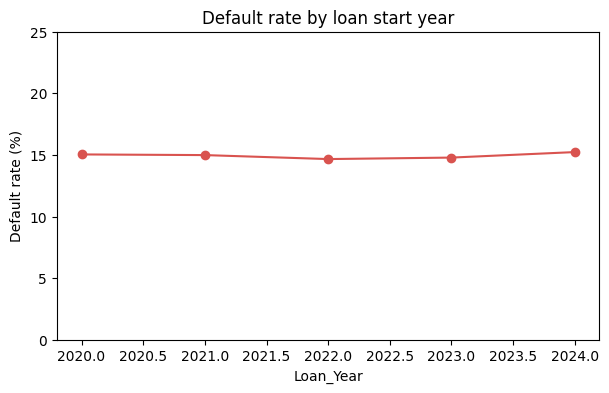

In [16]:
df["Loan_Start_Date"] = pd.to_datetime(df["Loan_Start_Date"])
df["Loan_Year"] = df["Loan_Start_Date"].dt.year

ax = (df.groupby("Loan_Year")["Default"].mean() * 100).plot(kind="line", marker="o", color="#d9534f")
ax.set_title("Default rate by loan start year")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(0, 25)
plt.show()

### 5.7 Correlation heatmap

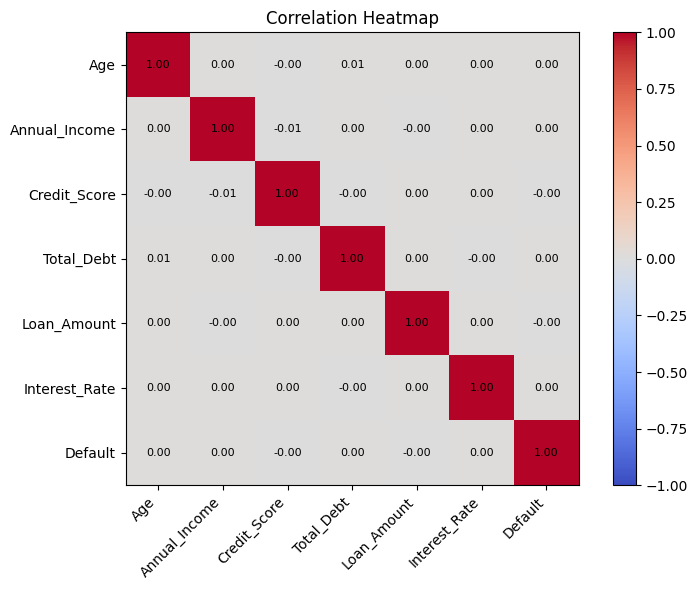

Correlation of each feature with Default:
Credit_Score    -0.0046
Loan_Amount     -0.0018
Annual_Income    0.0011
Age              0.0019
Total_Debt       0.0023
Interest_Rate    0.0041
Name: Default, dtype: float64


In [17]:
corr = df[num_cols + ["Default"]].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation of each feature with Default:")
print(corr["Default"].drop("Default").round(4).sort_values())

### EDA Summary
- The default rate is about **15%**, and it stays almost the same for **every** employment status, gender,
  loan term, credit-score band and loan year.
- The correlation of every feature with `Default` is **very close to 0**.
- This is an early warning that **these features may not contain much information about defaults**.
  We will test this properly with machine learning models in the next steps.

## Step 6: Feature Engineering

New features are built from the existing ones, based on how banks think about risk:

| New feature | Formula | Why it could matter |
|---|---|---|
| `Term_Months` | number extracted from `Loan_Term` | text → number |
| `Debt_to_Income` | Total_Debt / Annual_Income | how heavily indebted the customer already is |
| `Loan_to_Income` | Loan_Amount / Annual_Income | how big the loan is compared to earnings |
| `Monthly_Payment` | (Loan_Amount + simple interest) / Term_Months | approximate monthly burden |
| `Payment_to_Income` | Monthly_Payment × 12 / Annual_Income | share of yearly income used for repayment |

We **drop** columns that cannot help a model generalise: `Loan_ID`, `Customer_ID` (just labels),
`Name` (identifier, and using it would be unfair/irrelevant), and the raw dates.

In [18]:
def add_features(data):
    """Create new features. Used for training AND for predicting new applicants."""
    data = data.copy()
    data["Term_Months"] = data["Loan_Term"].str.extract(r"(\d+)")[0].astype(int)
    data["Debt_to_Income"] = data["Total_Debt"] / data["Annual_Income"]
    data["Loan_to_Income"] = data["Loan_Amount"] / data["Annual_Income"]
    data["Monthly_Payment"] = (data["Loan_Amount"] * (1 + data["Interest_Rate"] / 100 * data["Term_Months"] / 12)
                               / data["Term_Months"])
    data["Payment_to_Income"] = data["Monthly_Payment"] * 12 / data["Annual_Income"]
    return data

df_fe = add_features(df)

drop_cols = ["Loan_ID", "Customer_ID", "Name", "Loan_Term", "Loan_Start_Date", "Loan_Year"]
df_model = df_fe.drop(columns=drop_cols)
df_model.head()

,Loan_Amount,Interest_Rate,Default,Age,Gender,Annual_Income,Credit_Score,Total_Debt,Employment_Status,Term_Months,Debt_to_Income,Loan_to_Income,Monthly_Payment,Payment_to_Income
0,40594.38,13.93,0,46,Male,102522.56,746,24487.40,Unemployed,60,0.238849,0.395956,1147.806094,0.134348
1,38966.87,5.90,0,27,Male,83159.68,468,31885.15,Self-Employed,12,0.383421,0.468579,3438.826278,0.496225
2,29180.92,8.56,0,43,Female,42259.73,765,9312.03,Unemployed,60,0.220352,0.690514,694.505896,0.197211
3,31714.71,9.48,0,58,Female,33451.08,352,42480.11,Employed,48,1.269917,0.948092,911.269334,0.326902
4,19542.04,12.19,0,50,Male,124924.48,362,8041.98,Self-Employed,24,0.064375,0.156431,1012.766223,0.097284


### Encoding categorical columns
Machine learning models need numbers, so `Gender` and `Employment_Status` are converted with **one-hot encoding**
(`pd.get_dummies`). `drop_first=True` avoids redundant columns.

In [19]:
X = pd.get_dummies(df_model.drop(columns=["Default"]), columns=["Gender", "Employment_Status"], drop_first=True)
y = df_model["Default"]

print("Feature matrix shape:", X.shape)
print("Features used:", list(X.columns))

Feature matrix shape: (100000, 15)
Features used: ['Loan_Amount', 'Interest_Rate', 'Age', 'Annual_Income', 'Credit_Score', 'Total_Debt', 'Term_Months', 'Debt_to_Income', 'Loan_to_Income', 'Monthly_Payment', 'Payment_to_Income', 'Gender_Male', 'Employment_Status_Retired', 'Employment_Status_Self-Employed', 'Employment_Status_Unemployed']


## Step 7: Train–Test Split

80% of the data is used to train the model, and 20% is kept aside to test it on **unseen** loans.
`stratify=y` keeps the same default percentage (~15%) in both parts.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Default rate:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape,  "| Default rate:", round(y_test.mean() * 100, 2), "%")

Train: (80000, 15) | Default rate: 14.92 %
Test : (20000, 15) | Default rate: 14.92 %


## Step 8: Build the Models

We compare four models:

1. **Baseline (Dummy)** – always predicts "No Default". Every real model must beat this to be useful.
2. **Logistic Regression** – simple, fast, easy to explain (needs scaling, so it is used in a Pipeline).
3. **Decision Tree** – rule-based, easy to visualise.
4. **Random Forest** – many trees voting together; usually stronger.

Because defaults are rare, we use `class_weight="balanced"`, which tells the model to pay more attention
to the minority (default) class.

In [21]:
models = {
    "Baseline (always No Default)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Baseline (always No Default)
Trained: Logistic Regression


Trained: Decision Tree


Trained: Random Forest


## Step 9: Evaluate the Models

Metrics used (and why):

- **Accuracy** – % of correct predictions (misleading when classes are imbalanced).
- **Precision** – of the loans we flagged as "default", how many really defaulted?
- **Recall** – of all real defaults, how many did we catch? (very important for a bank)
- **F1-score** – balance of precision and recall.
- **ROC-AUC** – how well the model *ranks* risky loans above safe ones.
  **0.5 = random guessing, 1.0 = perfect.**

In [22]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Baseline (always No Default),0.8508,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.5170,0.1498,0.4787,0.2282,0.5040
Decision Tree,0.6288,0.1500,0.3191,0.2041,0.5024
Random Forest,0.6670,0.1517,0.2685,0.1939,0.5020


**Reading the table:**
- The baseline has high accuracy (~85%) but **recall = 0** – it never catches a single defaulter.
  This proves why accuracy alone cannot be trusted.
- Look at the **ROC-AUC** of the real models – how far is it from 0.5?

### 9.1 Confusion matrices

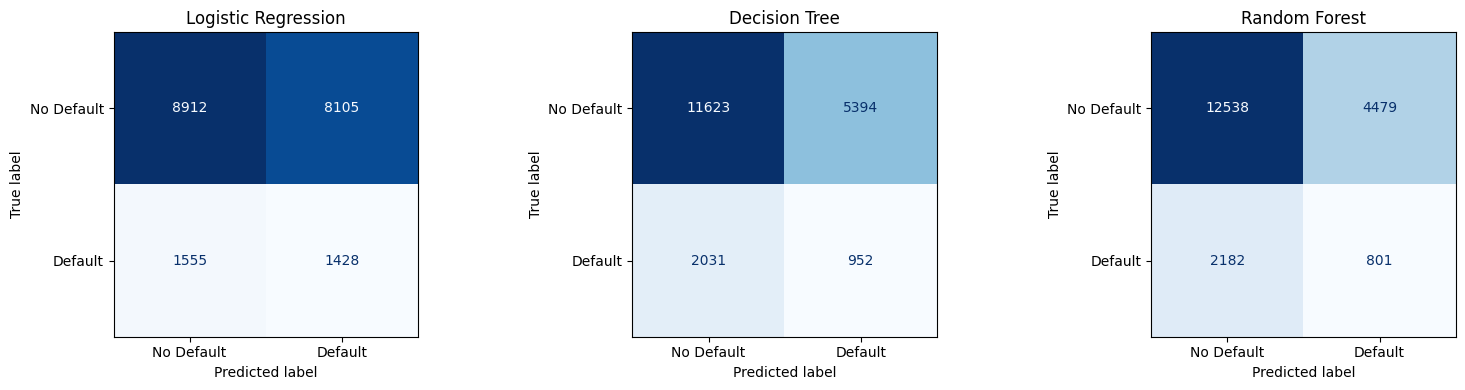

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(models[name], X_test, y_test, ax=ax,
                                          display_labels=["No Default", "Default"], cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 9.2 ROC curves

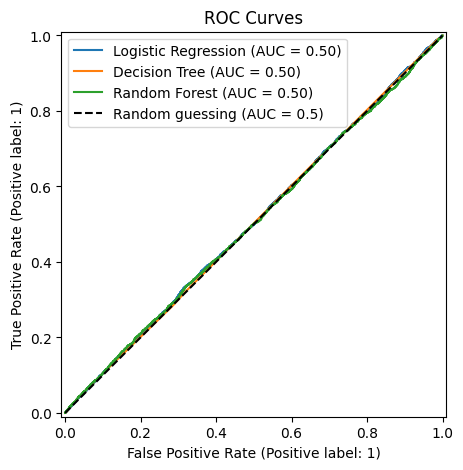

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
ax.set_title("ROC Curves")
ax.legend()
plt.show()

### 9.3 Detailed report for the Random Forest

In [25]:
print(classification_report(y_test, models["Random Forest"].predict(X_test),
                            target_names=["No Default", "Default"]))

              precision    recall  f1-score   support

  No Default       0.85      0.74      0.79     17017
     Default       0.15      0.27      0.19      2983

    accuracy                           0.67     20000
   macro avg       0.50      0.50      0.49     20000
weighted avg       0.75      0.67      0.70     20000



### 9.4 Which features did the Random Forest consider important?

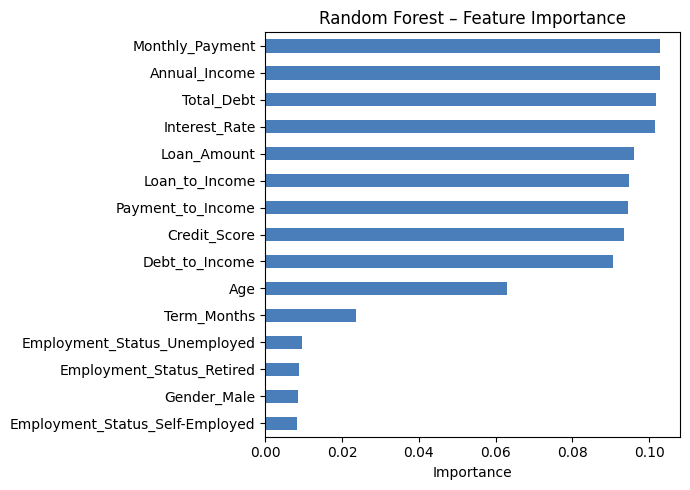

In [26]:
importances = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()

ax = importances.plot(kind="barh", color="#4a7ebb", figsize=(7, 5))
ax.set_title("Random Forest – Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

### 9.5 Cross-validation (a more reliable check)
A single train/test split can be lucky or unlucky. **5-fold cross-validation** trains and tests the model
5 times on different parts of the data and averages the ROC-AUC.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    scores = cross_val_score(models[name], X, y, cv=cv, scoring="roc_auc")
    print(f"{name:<22} ROC-AUC per fold: {np.round(scores, 3)}  |  mean = {scores.mean():.3f}")

Logistic Regression    ROC-AUC per fold: [0.494 0.502 0.5   0.503 0.506]  |  mean = 0.501


Decision Tree          ROC-AUC per fold: [0.502 0.495 0.495 0.497 0.496]  |  mean = 0.497


Random Forest          ROC-AUC per fold: [0.493 0.5   0.508 0.498 0.501]  |  mean = 0.500


## Step 10: Sanity Check – Is the Model Learning Anything Real?

If ROC-AUC is about 0.5, a good scientist asks: *"Is my code wrong, or is there just no signal in the data?"*
A quick test: **shuffle the labels randomly** (destroying any real relationship) and train again.
If the score on the real labels is the same as on shuffled labels, the model has learned nothing beyond chance.

In [28]:
rng = np.random.RandomState(RANDOM_STATE)
y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)

rf_shuffled = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced",
                                     n_jobs=-1, random_state=RANDOM_STATE)
rf_shuffled.fit(X_train, y_shuffled)

auc_real = roc_auc_score(y_test, models["Random Forest"].predict_proba(X_test)[:, 1])
auc_shuffled = roc_auc_score(y_test, rf_shuffled.predict_proba(X_test)[:, 1])

print(f"ROC-AUC with REAL labels     : {auc_real:.3f}")
print(f"ROC-AUC with SHUFFLED labels : {auc_shuffled:.3f}")

ROC-AUC with REAL labels     : 0.502
ROC-AUC with SHUFFLED labels : 0.494


## Step 11: Conclusion

**What we did:** merged three datasets (100,000 loans), explored them, engineered banking-style features
(debt-to-income, loan-to-income, payment-to-income), and compared a baseline with Logistic Regression,
Decision Tree and Random Forest using proper metrics and cross-validation.

**Key findings**
1. About **15%** of loans default → the data is **imbalanced**, so **accuracy is misleading**
   (the "always No Default" baseline gets ~85% accuracy but catches zero defaulters).
2. All three models have a **ROC-AUC of about 0.50**, which is the same as random guessing, and the
   cross-validation scores agree. The model trained on real labels scores the same as one trained on shuffled labels.
3. In the EDA, default rate was almost identical across all credit-score bands, employment types, genders,
   loan terms and years, and no feature had a meaningful correlation with default.

**Interpretation:** In this dataset, the available customer and loan details **do not carry usable information
about who will default**. This is not a coding mistake — it is a genuine finding, and it is why we checked
with a baseline, cross-validation and shuffled labels instead of only quoting accuracy.
Datasets like this are often **synthetic (computer-generated)**, where the default label is assigned
independently of the other columns. In real banking data, credit score, debt-to-income and similar features
are strongly linked to default.

**Limitations**
- Only 9 customer/loan attributes are available. Real credit models also use payment history, number of late
  payments, credit utilisation, collateral, loan purpose, etc.
- No hyperparameter tuning was done (it cannot create a signal that is not in the data).

**Future work**
- Test the same pipeline on a real-world dataset (e.g. Lending Club or German Credit) where the features are informative.
- Add richer features (payment history) and try gradient-boosting models (XGBoost/LightGBM).
- Use techniques such as SMOTE and threshold tuning to trade off precision and recall based on the bank's costs.

## Step 12: Use the Model for a New Applicant (Demo)

A small helper function that takes an applicant's details and returns the model's default risk score.
*(Since the data has almost no predictive signal, treat this output as a demonstration of the pipeline, not as real lending advice.)*

In [29]:
def predict_default_risk(age, gender, annual_income, credit_score, total_debt, employment_status,
                         loan_amount, interest_rate, loan_term_months, model=models["Random Forest"]):
    applicant = pd.DataFrame([{
        "Age": age, "Gender": gender, "Annual_Income": annual_income, "Credit_Score": credit_score,
        "Total_Debt": total_debt, "Employment_Status": employment_status,
        "Loan_Amount": loan_amount, "Interest_Rate": interest_rate,
        "Loan_Term": f"{loan_term_months} months",
    }])
    applicant = add_features(applicant).drop(columns=["Loan_Term"])
    applicant = pd.get_dummies(applicant, columns=["Gender", "Employment_Status"])
    applicant = applicant.reindex(columns=X.columns, fill_value=0)     # match training columns
    prob = model.predict_proba(applicant)[0, 1]
    return prob

prob = predict_default_risk(age=35, gender="Male", annual_income=80000, credit_score=650,
                            total_debt=20000, employment_status="Employed",
                            loan_amount=25000, interest_rate=9.5, loan_term_months=36)
print(f"Model score for default: {prob * 100:.1f}%")
print("Decision:", "HIGH RISK - review manually" if prob > 0.5 else "LOW RISK")
# Note: because we trained with class_weight="balanced", this score is not a true probability;
# it is only useful for ranking applicants from lower to higher risk.

Model score for default: 49.1%
Decision: LOW RISK
